In [15]:
import pandas as pd

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.csv"

cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
        "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]

df = pd.read_csv(url, header=None, names=cols)
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [16]:
import numpy as np

zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

df[zero_cols] = df[zero_cols].replace(0, np.nan)

df.isnull().sum()

,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [17]:
from sklearn.model_selection import train_test_split

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(614, 8) (154, 8)
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


In [18]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_train_imp = pd.DataFrame(imputer.fit_transform(X_train),
                           columns=X.columns, index=X_train.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test),
                          columns=X.columns, index=X_test.index)

print(dict(zip(X.columns, imputer.statistics_.round(1))))
print(X_train_imp.isnull().sum().sum(), X_test_imp.isnull().sum().sum())

{'Pregnancies': np.float64(3.0), 'Glucose': np.float64(117.0), 'BloodPressure': np.float64(72.0), 'SkinThickness': np.float64(29.0), 'Insulin': np.float64(125.0), 'BMI': np.float64(32.4), 'DiabetesPedigreeFunction': np.float64(0.4), 'Age': np.float64(29.0)}
0 0


In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

print(X_train_scaled.mean(axis=0).round(2))
print(X_train_scaled.std(axis=0).round(2))

[-0. -0.  0. -0. -0.  0. -0. -0.]
[1. 1. 1. 1. 1. 1. 1. 1.]


In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

log_model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)

y_pred = log_model.predict(X_test_scaled)
y_prob = log_model.predict_proba(X_test_scaled)[:, 1]

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

              precision    recall  f1-score   support

           0       0.82      0.75      0.79       100
           1       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154

[[75 25]
 [16 38]]
ROC-AUC: 0.813


              precision    recall  f1-score   support

           0       0.83      0.75      0.79       100
           1       0.61      0.72      0.66        54

    accuracy                           0.74       154
   macro avg       0.72      0.74      0.73       154
weighted avg       0.75      0.74      0.74       154

[[75 25]
 [15 39]]
ROC-AUC: 0.819


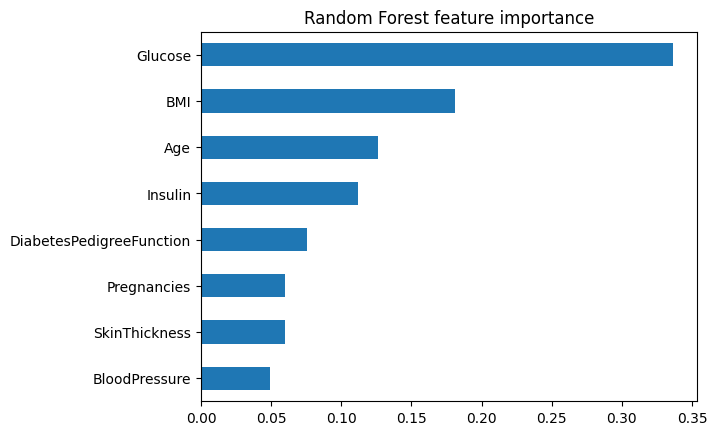

In [21]:
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=5, class_weight="balanced", random_state=42
)
rf_model.fit(X_train_imp, y_train)

rf_pred = rf_model.predict(X_test_imp)
rf_prob = rf_model.predict_proba(X_test_imp)[:, 1]

print(classification_report(y_test, rf_pred))
print(confusion_matrix(y_test, rf_pred))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 3))

importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()
importances.plot(kind="barh", title="Random Forest feature importance")
plt.show()

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "recall", "precision", "f1", "roc_auc"]

log_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
])

rf_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(n_estimators=200, max_depth=5,
                                     class_weight="balanced", random_state=42)),
])

results = {}
for name, pipe in [("Logistic Regression", log_pipe), ("Random Forest", rf_pipe)]:
    scores = cross_validate(pipe, X, y, cv=cv, scoring=scoring)
    results[name] = {m: scores[f"test_{m}"].mean() for m in scoring}

pd.DataFrame(results).T.round(3)

,accuracy,recall,precision,f1,roc_auc
Logistic Regression,0.747,0.727,0.623,0.669,0.836
Random Forest,0.763,0.765,0.636,0.693,0.837


In [23]:
import joblib

final_model = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(n_estimators=200, max_depth=5,
                                     class_weight="balanced", random_state=42)),
])

final_model.fit(X_train, y_train)

final_pred = final_model.predict(X_test)
print(classification_report(y_test, final_pred))
print(confusion_matrix(y_test, final_pred))

joblib.dump(final_model, "diabetes_rf_model.pkl")

              precision    recall  f1-score   support

           0       0.83      0.75      0.79       100
           1       0.61      0.72      0.66        54

    accuracy                           0.74       154
   macro avg       0.72      0.74      0.73       154
weighted avg       0.75      0.74      0.74       154

[[75 25]
 [15 39]]


['diabetes_rf_model.pkl']